In [1]:
import time

import cv2
from matplotlib import pyplot as plt
import numpy as np

!python -m pip install -q ultralytics
import ultralytics
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.1 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 410.6 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 259.8 kB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## **1. Basic Tracking Run**

In [2]:
def process_clip(cap, model, fname):
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total}")

    start = time.time()
    frame_ctr = 0

    # Count the total unique IDs that appeared across all frames
    unique_ids = set()

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Tracker used is ByteTrack (no ReID)
        results = model.track(frame, 
                              persist=True, 
                              classes=[2,3,5,7],
                              conf=0.25,
                              agnostic_nms=True,
                              verbose=False,
                              tracker="bytetrack.yaml")
        
        annot_res = results[0].plot(font_size=17, pil=True)

        if results[0].boxes.id is not None:
            unique_ids.update(results[0].boxes.id.int().tolist())

        # VideoWriter.write expects frames in BGR
        out.write(cv2.cvtColor(np.array(annot_res), cv2.COLOR_RGB2BGR))
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

# def playback(cap):
#     while cap.isOpened():
#         ret, frame = cap.read()

#         if not ret:
#             break

#         cv2.imshow("VideoPlayback", frame)

#         if cv2.waitKey(1) & 0xFF == ord("q"):
#             break

#     cap.release()
#     cv2.destroyAllWindows()

In [3]:
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
process_clip(cap1, model, "../outputs/output_track_overhead_medium_congest_01.mp4")

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 335ms
Prepared 1 package in 91ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 348
Duration: 929.7s
FPS: 3.1


### **Basic Tracking Run Observations**

**Note:** The annotated output clip produced in this run is available [here](https://youtu.be/orn_LDkvYcQ).   
The frame numbers, scenarios, and other tracking/detection results referenced in the observations below are from this specific clip.   
Running the same code may produce slightly different results due to differences in hardware.

**A. GENERAL**
- The clip shows medium traffic (counted as per the project-defined vehicles/lane/minute thresholds)
- One outgoing lane is congested almost throughout the entirety of the 2-minute video
- Track IDs (via ByteTrack) stay consistent as vehicles move across frames (even as vehicles change lanes) in this moderate traffic clip
- However cases of tracking and detection instabilities can still be observed. Below are some examples.

**B. ID TRANSFER CASE**  

Observed a case of ID transfer at frames 650-725 (0:00:26-:29) between two vehicles in the far zone.   
A car box had a detection dropout, and its id-552 was absorbed by another generated box close by.   
**What likely happened:**
  1. Vehicle 1 had a detection dropout for a few frames
  2. The tracker kept its predicted position via Kalman
  3. Vehicle 2’s detection was closer to that predicted position and took it.
     
Note that this ID transfer seen at frames 650-757 does not affect accurate counting since vehicle 1 was eventually assigned a new fresh ID as it got closer.

**C. CASCADING ID TRANSFERS**

Seen at frames 1450-1650 when an outgoing truck passes next to the congested right-most lane consisting of stationary trucks.   
Adjust playback to 0.25x speed for better observation.
  1. As the outgoing truck came into view, it was immediately assigned an ID 1078 (normal behavior)
     
  2. It transferred that ID to the first truck (`truck1`) in the congested lane as both vehicles overlapped.

     - During the overlap,`truck1` changed ID twice before acquiring ID 1078.
     - The outgoing truck is then newly-assigned to ID 1083.  
     - This ID transfer is visibly caused by the two objects overlapping
     - The outgoing track's Kalman prediction overlapped with `truck1` on the right, which took the ID.
     <br>
     <img src="assets/cascade-1475.png" width="800">
     <br><br>
  3. The outgoing truck passes `truck2` then abruptly switches ID from 1083 to 1100. `truck2`'s ID 219 persisted.
     - `truck2`'s box did not overlap with the outgoing vehicle enough to cause a bad matching
     <br>
  4. Upon passing `truck3` is when the cascading effect got worse. A merged detection between the passing truck and `truck3` on the right briefly occurred, with the merged box inheriting ID 1100
       <img src="assets/cascade-1525.png" width="800">
       <br>
  5. The merged detection is eventually corrected but ID 1100 was transferred to `truck3` for brief milliseconds.

  6. The moment the boxes separate, `truck3` is stationary and sitting right where the merged box was.

     - For this reason, it got the better IoU match and took ID 1100.
     <br>
  7. The outgoing truck is now treated as a new object and assigned ID 1117.

  8. It kept moving and eventually re-entered the region where track 1100’s Kalman prediction would have landed, reacquiring ID 1100 back

      - It can be seen that it first had a merged detection with `truck4` before reacquiring 1100.
     <br>
     <img src="assets/cascade-1550.png" width="800">
     <br>
  9. Meanwhile, `truck3` is now an inferior match to track 1100 so it was assigned to a new ID 1126.
  10. The outgoing truck also caused `truck4` in the congested lane to lose its original ID and acquire a new one (from ID 2 to 1153)    

**Root cause:** Tightly packed vehices naturally produce heavily overlapping boxes, which makes IoU alone insufficient in reliably distinguishing which detection belongs to which track, so ***one bad match in the Hungarian assignment cascades through the rest***. Note that in the Hungarian algorithm, one wrong cost (caused by a low *1 - IoU x confidence* between the wrong track-detection pair) can propagate to the entire global cost minimization. This algorithm does not match tracks to detections independently and every pairing affects every other pairing. We might look into using a different tracker that utilizes ReID to help maintain correct tracker-detection pairings even with congestion. ***The “cascading” part is that each collision’s damage propagates forward.*** The outgoing truck exits collision 1 (`truck1`) with a wrong ID (1073-->1083), which it brings into collision 2 (`truck2`), which produces another wrong ID (1100), which feeds into collision 3 then 4. If collision 1 produced correct results, collisions 2 and 3 either might never have happened or at least would be independent errors rather part of a chain.

**D. NO ID SWAPS ARE OBSERVED**
- A true ID swap is when two vehicles cleanly exchange IDs with each other (vehicle A gets B’s ID, while vehicle B gets A’s ID at the same time).
- What we have observed so far was a series of ID transfers and reassignments that are one-directional 
- While the IDs moved around many times, no two vehicles swapped IDs with each other in one single step.
- It is also possible I may have missed one or two instances while reviewing the two-minute video.
- But such occurrences are infrequent enough that they are not immediately observable in visual inspection.

**E. IDs ARE BEING ASSIGNED IMMEDIATELY ON NEW DETECTIONS**
- Looking at the output vid, an ID seems to be assigned immediately as soon as a box appears, even with low conf (0.2 - 0.3)
- The default confidence threshold for a box to appear is 0.25, which is also our ideal threshold
- Might be worth looking at the ByteTrack config file to know precisely the conf. threshold for IDs to be assigned.
- Looking at the config also reveals the default value of other important parameters like the number of no-detection frames before a track is lost.

In [4]:
# View ByteTrack's config yaml file to see default parameters
import yaml
from pathlib import Path

# Point to the cfg/trackers directory inside the ultralytics installation
cfg = yaml.safe_load(
    (Path(ultralytics.__file__).parent / "cfg" / "trackers" / "bytetrack.yaml").read_text())

for k, v in cfg.items():
    print(f"{k}: {v}")

tracker_type: bytetrack
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.25
track_buffer: 30
match_thresh: 0.8
fuse_score: True


### **Observations (Cont.)**

- `new_track_thresh: 0.25` means new, untracked boxes with conf scores >=0.25 is immediately assigned a track ID.
- This immediate ID assignment explains how low-confidence vehicles, as observed in the output clip, can get an ID right away (it was not a bug)
- The default `track_high_thresh: 0.25` is lower than the original [ByteTrack paper's](https://arxiv.org/abs/2110.06864) 0.6.
- This lower `track_high_threshold` (and `track_low_thresh`) mean every detection goes through ByteTrack's high-confidence, first-pass cost minimization.
- A `track_buffer` of 30 means a track can maintain non-pairing with a detection for 30 frames. It stays alive for that many frames before it loses its track ID
- The clip is 25 fps, meaning, an established track can be lost in just approximately 1 second.

## **2. Compare With and Without Agnostic NMS**

So far, we have been observing results that was generated with `agnostic_nms=True`. This suppresses duplicate boxes of different classes on the same vehicle. As we have seen in the `detection-running-video-analysis` experiment notebook, this is a clear win for detection. However, there is a possibility that inter-class suppression also removes some detections the tracker might have needed in order to maintain a track during occlusion. For instance, say vehicle A is partially occluded behind vehicle B. The detector might produce two overlapping boxes -- one for A (low confidence) and one for B (high confidence). With `agnostic_nms=True`, A’s box can be suppressed because it highly overlaps with B’s higher-scoring box, even though they are two different vehicle classes. 

This is a true possibility, but when you think about it, the *default IoU threshold for NMS suppression is 0.7*. So the only way NMS suppresses a real vehicle’s box is if it overlaps by more than 70% with another higher-confidence vehicle. Visually, that should look like both vehicles' boxes are nearly on top of each other. In a real traffic scene, that’s extremely rare between two separate vehicles. For instance, a car partially behind a truck might look heavily occluded, but the car’s detection box (if the model even produces one) is usually much smaller and positioned differently than the truck’s box. This means, for most cases, NMS will only suppress duplicate, different-class boxes on the same vehicle. For two different but highly overlapping vehicles, either the detection fails first before NMS due to total occlusion OR the detection persists because it is difficult to exceed an IoU of >0.7. Still, rather than relying on reasoning alone, we run the test to see what actually happens when agnostic NMS is turned off. We will use the same clip as above but with `agnostic_nms=False`.

In [5]:
# Modify the process_clip function to make agnostic_nms parameter configurable
def process_clip(cap, model, fname, ag_nms=True):
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total}")

    start = time.time()
    frame_ctr = 0

    # Count the total unique IDs that appeared across all frames
    unique_ids = set()

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Tracker used is ByteTrack (no ReID)
        results = model.track(frame, 
                              persist=True, 
                              classes=[2,3,5,7],
                              conf=0.25,
                              agnostic_nms=ag_nms,
                              verbose=False,
                              tracker="bytetrack.yaml")
        
        annot_res = results[0].plot(font_size=17, pil=True)

        if results[0].boxes.id is not None:
            unique_ids.update(results[0].boxes.id.int().tolist())

        # VideoWriter.write expects frames in BGR
        out.write(cv2.cvtColor(np.array(annot_res), cv2.COLOR_RGB2BGR))
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

In [6]:
model.predictor = None
cap2 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
process_clip(cap2, model, "../outputs/output_track_overhead_medium_congest_01_agnmsfalse.mp4", ag_nms=False)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 470
Duration: 915.4s
FPS: 3.1


### **Observations (`agnostic_nms=False`)**

**Note:** The annotated output clip produced in this run is available [here](https://youtu.be/vmwfw2UrEho).   
The frame numbers, scenarios, and other tracking/detection results referenced in the observations below are from this specific clip.   
Running the same code may produce slightly different results due to differences in hardware.

- The total unique IDs increased from 348 to 470 (a 35% increase) with `agnostic_nms=False`
- This increase in total IDs is likely from duplicate, different-class boxes on the same vehicle each spawning their own track ID.
- Non-agnostic NMS does not touch cross-class duplicates, so a vehicle that saw a detection of two classes will keep both boxes and IDs.
- Duplicate detections appeared mostly on vehicles where the model was undecided on class 
- An example is seen at frames 135-1435 where two vans having a car and truck box at the same time. Each box spawned its own track ID.  
  <br>
  <img src="assets/duplicate-detect-1375.png">
  <br>
- The congested lane behavior at frames 1450–1650 remain identical. We can see the same cascade pattern with ID transfers and merged detections occuring.
- This is expected because the cascade effect is a tracker-side problem. The cascade happens even without total occlusion, so NMS settings don't affect this.
- The key point is that the cascade happens because the closely-spaced boxes produce similar IoU scores, making the tracker misassign detections to wrong tracks.
- Throughout the clip, no cases were found where the extra non-suppressed boxes helped the tracker maintain a track through occlusion.

For now, we will use `agnostic_nms=True` as the setting for counting. Turning it off unneccesarily adds duplicate tracks (35% more in this case) without any observable improvement. However, we cannot conclude that this is the right setting for every scenario because we only tested on one clip. A different scene with heavier intra-class occlusions might still produce different results, though at the default 0.7 IoU suppression threshold, it remains unlikely that agnostic NMS would remove a detection the tracker genuinely needed.

## **3. Track ID Stability in the Reliable Detection Zone**

Using the first output clip with `agnostic_nms=True`, we inspect vehicles in the reliable detection zone at 0.25x speed. The *reliable detection zone* is close to the camera for both incoming and outgoing lanes. The last 1-2 seconds before incoming vehicles exit the view at normal speed.

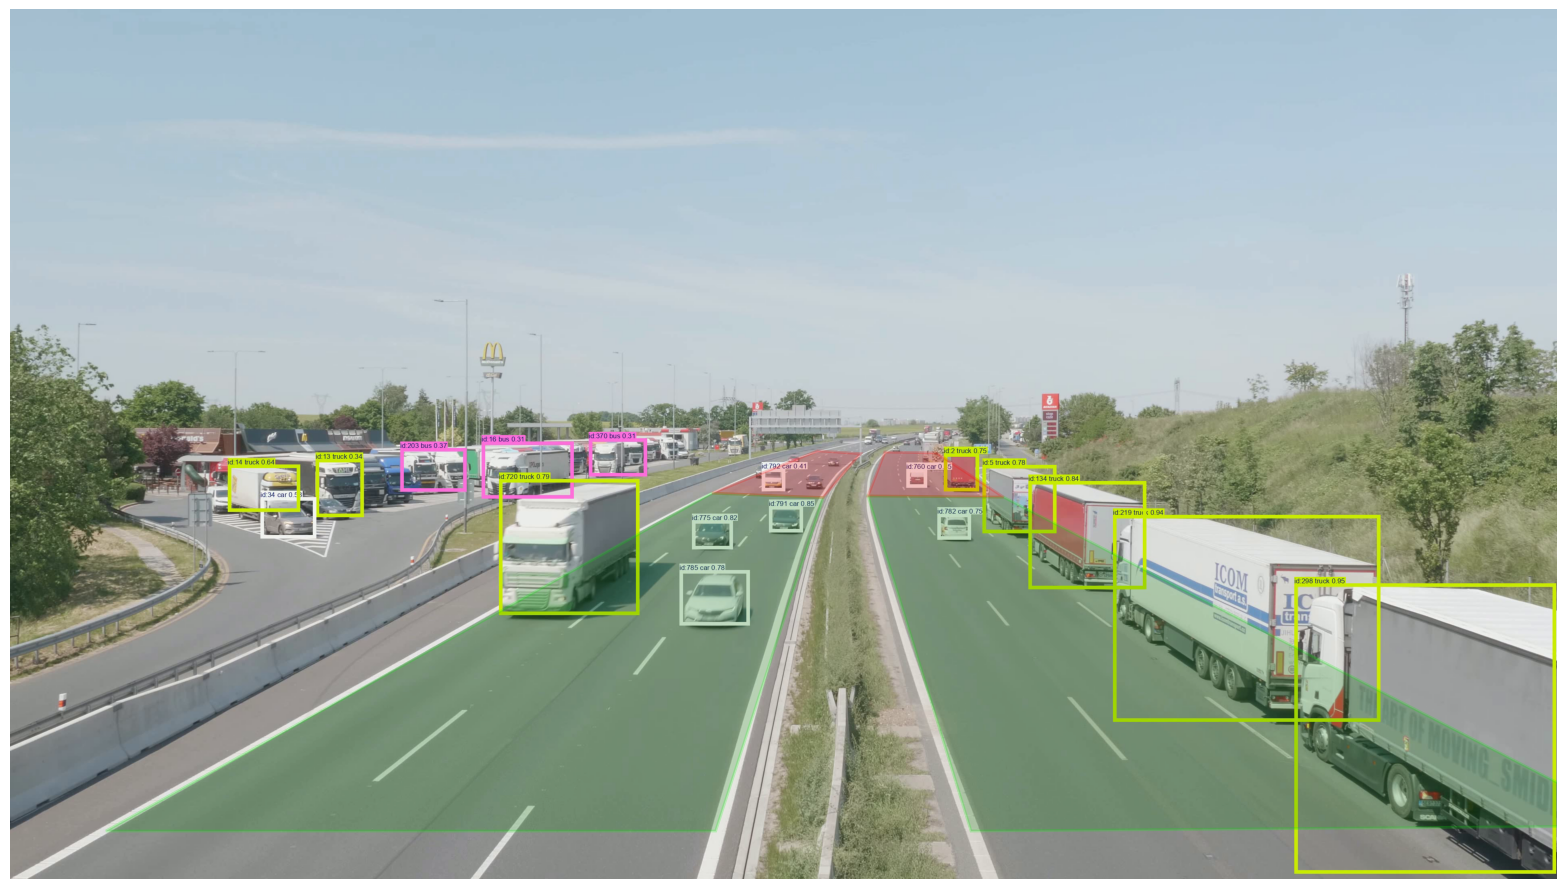

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
from PIL import Image

img = Image.open("assets/rdz-fz-nohighlight.png")  

fig, ax = plt.subplots(1, figsize=(16, 9))
ax.imshow(img)

left_rdz_zpoints = [(238, 2041),  # bottom-left corner
                    (1743, 1202),  # top-left corner
                    (2019, 1213),  # top-right corner
                    (1752, 2041)] # bottom-right corner

left_farzone_zp = [(1743, 1202),  # bottom-left corner
                   (2005, 1097),  # top-left corner
                   (2112, 1104),  # top-right corner
                   (2019, 1213)]  # bottom-right corner

right_rdz_zpoints = [(2386, 2041),  # bottom-left corner
                    (2130, 1209),  # top-left corner
                    (2467, 1212),  # top-right corner
                    (4050, 2028)] # bottom-right corner

right_farzone_zp = [(2130, 1209),  # bottom-left corner
                   (2172, 1100),  # top-left corner
                   (2300, 1102),  # top-right corner
                   (2467, 1212)]  # bottom-right corner

left_rdz = Polygon(left_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

left_fz = Polygon(left_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

right_rdz = Polygon(right_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

right_fz = Polygon(right_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

ax.add_patch(left_rdz), ax.add_patch(left_fz)
ax.add_patch(right_rdz), ax.add_patch(right_fz)

w, h = img.size
ax.set_xlim(0, w)
ax.set_ylim(h, 0) 
ax.axis('off')
plt.tight_layout()
# plt.savefig("assets/rdz-fz-highlighted.png", dpi=150, bbox_inches='tight')
plt.show()

**Incoming Lanes:**
- Track IDs are stable in the left incoming lanes, with vehicles maintaining their assigned IDs until exit
- This stability is expected since traffic on the incoming side is moderate without occlusions
- There are cases of class flickering (van oscillating between car and truck) but no ID changes or switches.
- Detection dropouts and the ID transfer observed in the previous experiments occurred in the far zone (not in the reliable zone)

**Outgoing Lanes:**
- Vehicles appearing into view frequently start with oversized bounding boxes which are corrected after a few frames.
- This is not a rare case. It appears the detector needs at least a few frames to settle on the correct box size for newly entering vehicles.
- For smaller vehicles (non-trucks), IDs survive and maintained going through the reliable zone, even next to the congested lane.
- For trucks, we see the same ID issues as observed above. Their size trigger detection merges and cascading ID transfers in the congested lane.

**Note:** Even if a vehicle entered the reliable zone with a wrong ID (for example, it took the ID of an overlapping car in the far zone or inherited a stationary ID from the congested lane), that vehicle may hold that wrong ID consistently as it goes through the reliable zone. The tracking itself seem stable, even though it has the wrong ID assignment.

## **4. Inspect the Output Objects**

In [8]:
# Modify the process_clip function once more. 
# Add a means to collect per-frame data and return it at the end
def process_clip(cap, model, fname, ag_nms=True):
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total}")

    start = time.time()
    frame_ctr = 0

    # Count the total unique IDs that appeared across all frames
    unique_ids = set()

    # Store Results object for each frame
    all_frames = []

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Tracker used is ByteTrack (no ReID)
        results = model.track(frame, 
                              persist=True, 
                              classes=[2,3,5,7],
                              conf=0.25,
                              agnostic_nms=ag_nms,
                              verbose=False,
                              tracker="bytetrack.yaml")
            
        # Store results in this dictionary then append to all_frames
        frame_data = {
            "frame": frame_ctr,
            "boxes": results[0].boxes.xyxy.cpu().numpy(),
            "ids": results[0].boxes.id.int().cpu().tolist() if results[0].boxes.id is not None else [],
            "confs": results[0].boxes.conf.cpu().tolist(),
            "classes": results[0].boxes.cls.int().cpu().tolist()
            }

        all_frames.append(frame_data)
        
        annot_res = results[0].plot(font_size=17, pil=True)

        if results[0].boxes.id is not None:
            unique_ids.update(results[0].boxes.id.int().tolist())

        # VideoWriter.write expects frames in BGR
        out.write(cv2.cvtColor(np.array(annot_res), cv2.COLOR_RGB2BGR))
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total} processed")

    elapsed = time.time() - start 
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

    return all_frames, unique_ids

In [9]:
# model inference run (third run) but this time it captures per-frame results
model.predictor = None
cap3 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")

# Overwrites the previous file of the same name
# Note: this run will with agnostic_nms=True as per our ideal setting
results = process_clip(cap3, model, "../outputs/output_track_overhead_medium_congest_01.mp4")

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 348
Duration: 901.1s
FPS: 3.2


In [10]:
import pandas as pd

def show_results_df(frame_res):
    boxes = frame_res["boxes"]
    
    frame_df = pd.DataFrame({
        "x1": boxes[:, 0],
        "y1": boxes[:, 1],
        "x2": boxes[:, 2],
        "y2": boxes[:, 3],
        "confidence_score": frame_res["confs"],
        "class_id": frame_res["classes"],
        "track_id": frame_res["ids"]
    })
    
    return frame_df

frame0 = results[0][0]
frame0_res = show_results_df(frame0)
frame0_res

,x1,y1,x2,y2,confidence_score,class_id,track_id
0,2743.390625,1662.041260,3049.720703,1864.423096,0.865052,2,1
1,2374.211914,1121.435669,2511.255371,1260.586304,0.799770,7,2
2,540.400085,1264.972900,672.260925,1352.787354,0.770930,2,3
3,1235.866699,1306.817139,1438.973145,1506.398682,0.759669,2,4
4,2582.864502,1197.118896,2949.613037,1505.133057,0.744830,7,5
5,2408.391113,1321.682861,2537.659180,1409.561279,0.730201,2,6
6,1666.215088,1258.773682,1772.333496,1355.849365,0.652795,2,7
7,627.162354,1225.106445,762.924561,1314.729980,0.630325,2,8
8,1728.184204,1193.528564,1788.551147,1245.495361,0.613320,2,9
9,2238.066650,1142.632080,2310.345459,1233.818604,0.585166,7,10


**Observations:**

- `track_id` starts at 1. This is the first frame in the clip so every detection starts its own new track
- `confidence_score`s are descending by confidence, which is YOLO's default output order for `.predict()` and `.track()`
- All entries are above `confidence_score` of 0.25, which aligns with the default conf we settled with in the `detection-per-frame` notebook experiment
- Bottom rows (track ID 19 and 20) are barely above 0.25.
- These low confidence detections are the most likely to flicker in and out across frames, causing tracking instabilities we documented earlier
- Only two classes are present. `class_id` has a mix of 2 (car) and 7 (truck), with no buses or motorcycles

In [12]:
results[0][100]

{'frame': 100,
 'boxes': array([[     2234.8,      1168.9,      2291.7,      1211.1],
        [     2349.1,      1100.3,      2474.3,      1241.2],
        [     2490.3,      1157.8,        2725,      1385.2],
        [     766.42,      1121.6,      876.57,      1249.1],
        [     541.84,      1131.8,      722.27,      1250.6],
        [     622.08,      1213.5,      762.92,      1314.3],
        [       2274,      1084.9,        2354,      1177.2],
        [       1173,      1076.4,      1391.7,      1209.7],
        [     2201.8,      1090.3,      2244.4,      1140.1],
        [     906.16,      1108.5,      1021.4,      1228.2],
        [     1832.9,      1172.6,      1908.6,      1232.8]], dtype=float32),
 'ids': [1, 2, 5, 13, 14, 34, 17, 16, 26, 77, 61],
 'confs': [0.6056879162788391,
  0.7592348456382751,
  0.779492199420929,
  0.3861185610294342,
  0.6334357261657715,
  0.5844150185585022,
  0.36172622442245483,
  0.36744847893714905,
  0.2873487174510956,
  0.27836078405380

In [13]:
for frame_idx in range(100, 103):
    frame = results[0][frame_idx]
    frame_res = show_results_df(frame)
    print(f"Frame {frame_idx}")
    display(frame_res)

Frame 100


,x1,y1,x2,y2,confidence_score,class_id,track_id
0,2234.788818,1168.885986,2291.711914,1211.119141,0.605688,2,1
1,2349.135742,1100.259888,2474.283691,1241.216064,0.759235,7,2
2,2490.318115,1157.845215,2724.998779,1385.211060,0.779492,7,5
3,766.416321,1121.601196,876.574646,1249.123901,0.386119,7,13
4,541.844543,1131.784790,722.274780,1250.570679,0.633436,7,14
5,622.077942,1213.497559,762.920898,1314.292847,0.584415,2,34
6,2274.043945,1084.921265,2354.013184,1177.158447,0.361726,7,17
7,1172.984863,1076.369873,1391.654419,1209.748413,0.367448,7,16
8,2201.789307,1090.319946,2244.390869,1140.101929,0.287349,7,26
9,906.155762,1108.454346,1021.364990,1228.242432,0.278361,7,77


Frame 101


,x1,y1,x2,y2,confidence_score,class_id,track_id
0,2230.720703,1162.218384,2293.789307,1209.631348,0.456490,2,1
1,2349.157959,1100.305908,2474.101807,1240.944092,0.750746,7,2
2,2489.786865,1157.888916,2723.033447,1383.587769,0.773247,7,5
3,766.431763,1121.718628,876.499146,1249.148926,0.392253,7,13
4,541.668762,1131.797974,722.395874,1250.847412,0.638445,7,14
5,622.654175,1214.246460,762.626160,1314.320923,0.601420,2,34
6,2273.933838,1084.464966,2354.186279,1177.082886,0.358019,7,17
7,1172.504761,1076.301147,1390.783569,1209.101440,0.357962,7,16
8,2201.934082,1089.932007,2244.101318,1138.755371,0.274106,7,26
9,910.478516,1112.044189,1021.371399,1227.363281,0.268306,7,77


Frame 102


,x1,y1,x2,y2,confidence_score,class_id,track_id
0,2229.378662,1158.780518,2292.395752,1206.758057,0.346820,2,1
1,2349.256348,1100.378784,2474.007080,1240.752441,0.759997,7,2
2,2490.224365,1157.853516,2721.836914,1381.755859,0.725316,7,5
3,766.764099,1121.879883,876.641968,1249.086548,0.374614,7,13
4,541.485107,1131.610840,722.275696,1250.743652,0.633054,7,14
5,622.890503,1214.543091,762.601013,1314.339111,0.605324,2,34
6,2274.218018,1084.341797,2354.412109,1177.022949,0.390261,7,17
7,1172.040771,1076.336304,1390.661255,1209.103638,0.348876,7,16
8,2200.715088,1088.806763,2243.389648,1138.218872,0.291982,7,26
9,907.335999,1109.751831,1021.155212,1227.948853,0.279902,7,77


**Verified:**
- The track IDs assigned are all integers
- The same vehicles keep the same ID. We can verify looking at the succession of box coordinates, class_id, and track_id combinations across 3 frames.

## **5. Tracking Instabilities Guide**

Just like detection had its instabilities (dropout, class flicker, split detection, merged detection), tracking has its own set as well and we define them here to serve as reference. 

| Instability | What happens | Impact on counting |
|-------------|--------------|--------------------|
| `ID transfer` | Vehicle A's ID jumps to vehicle B (usually after A's detection drops out and B is closer to A's Kalman prediction) | A gets a new ID. Double-counted only if one object produces a second crossing event under its new ID |
| `ID switch (swap)` | Two vehicles cleanly exchange IDs in a single step | None for event-wise counts but track history is swapped |
| `Track fragmentation` | One vehicle's journey split into multiple short tracks (repeated ID transfers or dropouts exceeding `track_buffer`) | Duplicate-counting only if somehow, individual fragments produce a crossing event |
| `Ghost track` | Track persists via Kalman prediction after the vehicle has left the frame | Counted if the "ghost" crosses the counting line, depending on implementation (more on to this later) |
| `Premature termination` | Track dies before vehicle reaches the counting line (detection lost for > `track_buffer` frames) | Missed count if no new track crosses the line |
| `Cascading ID transfers` | One bad match propagates through the Hungarian assignment, resulting in a chain of ID transfers across multiple nearby vehicles | Missed or duplicate crossings only if the chain drops a track before the line or moves a track across it twice. Case-to-case with misses and duplicates; non-preferred behavior nonetheless. |
| `Detection merge --> ID inheritance` | Two vehicles merges into one box, merged box inherits one vehicle's ID, the other track goes unmatched | Missed count if the unmatched track does not recover, otherwise feeds into transfers or cascades |

## **6. Tune `track_buffer` Parameter**

The default track_buffer is 30 frames (at \~1 second at 30fps). This controls how long the tracker allows a “lost” track to persist before permanently removing it from the active track pool. We know that in congested scenes, vehicles frequently occlude each other at varying durations across frames. If the buffer is too short, the tracker deletes the track and assigns a new ID when the vehicle reappears. Increasing the buffer length to 60 frames (~2 seconds) gives the tracker more time to re-associate a detection with its original track after a temporary occlusion, which can potentially reduce track fragmentation in the congested lane.

In [14]:
from ultralytics.cfg import SETTINGS
print(SETTINGS)

JSONDict("/root/.config/Ultralytics/settings.json"):
{
  "settings_version": "0.0.8",
  "datasets_dir": "/kaggle/working/datasets",
  "weights_dir": "weights",
  "runs_dir": "runs",
  "uuid": "859f0c19a621c3fec1551e0a891fdd9808bfb8e8979450ea19234aceead652f7",
  "sync": true,
  "api_key": "",
  "openai_api_key": "",
  "clearml": true,
  "comet": true,
  "dvc": true,
  "mlflow": true,
  "raytune": true,
  "tensorboard": false,
  "wandb": false,
  "vscode_msg": true,
  "openvino_msg": true
}


In [15]:
print(ultralytics.__file__)

/usr/local/lib/python3.13/dist-packages/ultralytics/__init__.py


In [16]:
# Copy the default config and make a variant 
# so we do not have to touch the original config file
# Each experiment moving forward will contain its own config file

# Load the default config
default_cfg = Path(ultralytics.__file__).parent / "cfg/trackers/bytetrack.yaml"
config = yaml.safe_load(default_cfg.read_text())

config["track_buffer"] = 60
Path(f"bytetrack_w_buffer{60}.yaml").write_text(yaml.dump(config))

145

In [17]:
# Modify process clip again so this time we can add a custom config file
def process_clip(cap, model, fname, ag_nms=True, track_file="bytetrack.yaml"):
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total}")

    start = time.time()
    frame_ctr = 0

    # Count the total unique IDs that appeared across all frames
    unique_ids = set()

    # Store Results object for each frame
    all_frames = []

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Tracker used is ByteTrack (no ReID)
        results = model.track(frame, 
                              persist=True, 
                              classes=[2,3,5,7],
                              conf=0.25,
                              agnostic_nms=ag_nms,
                              verbose=False,
                              tracker=track_file)
            
        # Store results in this dictionary then append to all_frames
        frame_data = {
            "frame": frame_ctr,
            "boxes": results[0].boxes.xyxy.cpu().numpy(),
            "ids": results[0].boxes.id.int().cpu().tolist() if results[0].boxes.id is not None else [],
            "confs": results[0].boxes.conf.cpu().tolist(),
            "classes": results[0].boxes.cls.int().cpu().tolist()
            }

        all_frames.append(frame_data)
        
        annot_res = results[0].plot(font_size=17, pil=True)

        if results[0].boxes.id is not None:
            unique_ids.update(results[0].boxes.id.int().tolist())

        # VideoWriter.write expects frames in BGR
        out.write(cv2.cvtColor(np.array(annot_res), cv2.COLOR_RGB2BGR))
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total} processed")

    elapsed = time.time() - start 
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

    return all_frames, unique_ids

In [18]:
model.predictor = None
cap4 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
res_buffer15 = process_clip(cap=cap4, 
                             model=model, 
                             fname="../outputs/output_track_overhead_medium_congest_01_buffer60.mp4", 
                             ag_nms=True,
                             track_file="../config/bytetrack_w_buffer60.yaml") 

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 331
Duration: 902.0s
FPS: 3.2


### **Observations**

**Note:** The annotated output clip produced in this run is available [here](https://youtu.be/Ld5EfNk75Rc).   
The tracking/detection results and patterns referenced in the observations below are from this specific clip.   
Running the same code may produce slightly different results due to differences in hardware.

- The total ID went from 348 in the previous run (buffer=30) to 331 (buffer=60). Both runs are with `agnostic_nms=True`
- The congestion cascade at frames 1450–1650 still occurs with patterns of ID transfers, reclamations, and new assignments, though they occur in different sequences
- We can however observe that tracks persist longer, and they can outlast an occlusion.
- For instance, at timestamp 0:01:37 - 41, we can observe ID 1047 in the congested lane was reclaimed after being occluded by a passing truck for ~2 seconds. That same object lost it's original ID at `track_buffer=30`
- Ghost tracks are not a concern in this clip’s geometry because vehicles enter and exit on separate lanes, so a lingering track’s predicted position would not overlap with a new vehicle’s detection

**Conclusion.** No visible downside so far at `track_buffer=60` and we actually saw a concrete improvement. This run had a 5% fewer unique IDs and tracks can survive longer through occlusions. We will keep it at 60 for now instead of the default 30.